# Machine-learning evaluation

Executed learning notebook for the Public Feedback Intelligence Platform.

Accuracy answers how often the model was correct overall. Precision asks how many predicted members of a class were correct; recall asks how many true members were found. Macro-F1 gives each class equal weight and is useful when classes differ in size.

In [1]:
import json
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
metrics = json.loads((ROOT / "artifacts" / "reports" / "model-metrics.json").read_text())
classifier = metrics["priority_classifier"]
regressor = metrics["resolution_regressor"]
pd.DataFrame({
    "metric": ["accuracy", "macro precision", "macro recall", "macro F1", "MAE (hours)", "R squared"],
    "value": [classifier["accuracy"], classifier["macro_precision"], classifier["macro_recall"], classifier["macro_f1"], regressor["mae_hours"], regressor["r2"]],
}).round(3)

,metric,value
0,accuracy,0.811
1,macro precision,0.802
2,macro recall,0.795
3,macro F1,0.799
4,MAE (hours),6.774
5,R squared,0.421


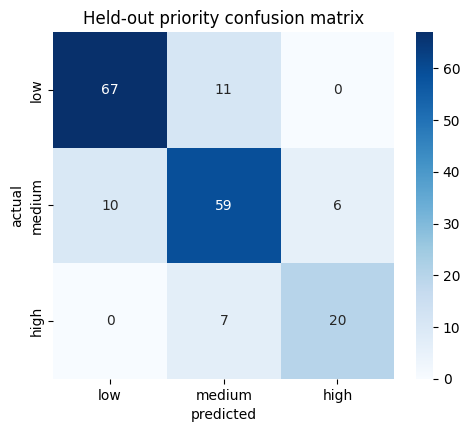

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = classifier["labels"]
matrix = classifier["confusion_matrix"]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set(xlabel="predicted", ylabel="actual", title="Held-out priority confusion matrix")
plt.show()

Preprocessing is fitted only on the training split. Resolution outcomes and satisfaction are excluded from priority prediction, preventing obvious target leakage.

In [3]:
from feedback_intelligence.modeling import predict_priority, predict_resolution

sample = {
    "title": "Workspace reloads during editing",
    "message": "Users lose unsaved work when the editor refreshes unexpectedly.",
    "category": "reliability",
    "channel": "web",
    "product": "workspace",
    "status": "open",
    "affected_users": 95,
    "attachment_count": 2,
    "priority": "high",
}
print(predict_priority(sample))
print(predict_resolution(sample))

{'priority': 'medium', 'probabilities': {'high': 0.0006282648962773445, 'low': 0.012303847354704274, 'medium': 0.9870678877490184}}
{'estimated_resolution_hours': 41.44}
